In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = "/content/drive/MyDrive/CPH100 Data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3.zip"
EXTRACT_DIR = "/content/CPH100_data"

!mkdir -p "$EXTRACT_DIR"
!unzip -o "$ZIP_PATH" -d "$EXTRACT_DIR"

Mounted at /content/drive
Archive:  /content/drive/MyDrive/CPH100 Data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3.zip
 extracting: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/LICENSE.txt  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/SHA256SUMS.txt  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/department.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/diagnosis.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/icd10_excluded.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3/labs.csv  
  inflating: /content/CPH100_data/inspire-a-publicly-available-research-dataset-for-pe

In [ ]:
#import libraries
import torch
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
GLOBALSEED = 42

In [ ]:

cd CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3

/content/CPH100_data/inspire-a-publicly-available-research-dataset-for-perioperative-medicine-1.3


In [ ]:
#import schemas and data (around 1 minute to load)
schemas = pd.read_csv("schema.csv")
operations = pd.read_csv("operations.csv")
vitals = pd.read_csv("vitals.csv")

# department = pd.read_csv("department.csv")
# icd10_excluded = pd.read_csv("icd10_excluded.csv")
labs = pd.read_csv("labs.csv")
# medications = pd.read_csv("medications.csv")
# parameters = pd.read_csv("parameters.csv")
# ward_vitals = pd.read_csv("ward_vitals.csv")
# diagnosis = pd.read_csv("diagnosis.csv")

# Data Exploration
## Missing Values

[Text(0, 0, '0'),
 Text(0, 0, '0'),
 Text(0, 0, '0'),
 Text(0, 0, '0'),
 Text(0, 0, '8.39951e-05'),
 Text(0, 0, '9.1631e-05'),
 Text(0, 0, '0.000404704'),
 Text(0, 0, '0.00271075'),
 Text(0, 0, '0.846411'),
 Text(0, 0, '0.885912'),
 Text(0, 0, '0.885912'),
 Text(0, 0, '0.980742'),
 Text(0, 0, '0.980742'),
 Text(0, 0, '0.988126')]

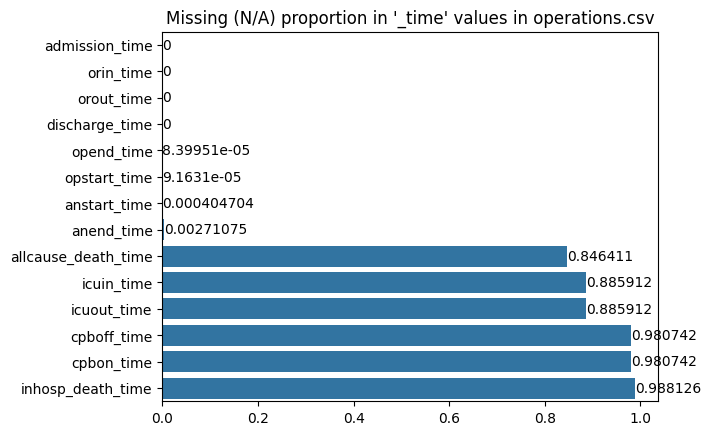

In [ ]:
time_columns = [c for c in operations.columns if "time" in c]
time_in_order = [
    "admission_time",
    "orin_time",
    "anstart_time",
    "opstart_time",
    "cpbon_time",
    "cpboff_time",
    "opend_time",
    "orout_time",
    "anend_time",
    "icuin_time",
    "icuout_time",
    "inhosp_death_time",
    "discharge_time",
    "allcause_death_time"
]

temp_times_df = operations[time_in_order].sub(operations["admission_time"], axis=0)

missing_times = temp_times_df.isna().mean().sort_values()
plt.title("Missing (N/A) proportion in '_time' values in operations.csv")
ax = sns.barplot(missing_times, orient="h")
ax.bar_label(ax.containers[0])

## Operations Table

In [ ]:
operations

,op_id,subject_id,hadm_id,case_id,opdate,age,sex,weight,height,race,...,admission_time,discharge_time,anstart_time,anend_time,cpbon_time,cpboff_time,icuin_time,icuout_time,inhosp_death_time,allcause_death_time
0,484069807,178742874,229842382,NaN,0,30,F,50.0,155.0,Asian,...,0,7195,1120.0,1235.0,NaN,NaN,NaN,NaN,NaN,NaN
1,446270725,158995752,257857903,NaN,0,70,M,45.0,170.0,Asian,...,0,70555,1345.0,1540.0,NaN,NaN,1550.0,19595.0,69860.0,106560.0
2,406892271,108553242,200664328,NaN,61920,50,F,70.0,165.0,Asian,...,0,178555,62170.0,62370.0,NaN,NaN,NaN,NaN,NaN,718560.0
3,478413008,133278262,277235295,NaN,0,35,F,55.0,NaN,Asian,...,0,5755,215.0,340.0,NaN,NaN,NaN,NaN,NaN,NaN
4,468516791,116924034,299190423,NaN,17280,45,F,45.0,150.0,Asian,...,0,25915,17950.0,18070.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130955,449124488,138484174,228449654,NaN,4999680,50,F,60.0,160.0,Asian,...,4996800,5012635,5000390.0,5000570.0,NaN,NaN,NaN,NaN,NaN,NaN
130956,461252752,126772283,273139806,NaN,2880,70,F,55.0,160.0,Asian,...,0,7195,3355.0,3430.0,NaN,NaN,NaN,NaN,NaN,NaN
130957,471834474,144363433,275833861,NaN,2880,65,F,50.0,150.0,Asian,...,0,11515,3595.0,3670.0,NaN,NaN,NaN,NaN,NaN,NaN
130958,419787421,195835964,293939099,NaN,12960,85,M,75.0,170.0,Asian,...,0,27355,13780.0,13950.0,NaN,NaN,13955.0,15120.0,NaN,613440.0


### Times Plotted in Order

In [ ]:
time_columns = [c for c in operations.columns if "time" in c]
time_in_order = [
    "admission_time",
    "orin_time",
    "anstart_time",
    "opstart_time",
    "cpbon_time",
    "cpboff_time",
    "opend_time",
    "orout_time",
    "anend_time",
    # "icuin_time",
    # "icuout_time",
    "inhosp_death_time",
    "discharge_time",
    "allcause_death_time"
]

times_df = operations[time_in_order].sub(operations["admission_time"], axis=0)

In [ ]:
times_df["monotonic"] = times_df.apply(lambda r: r.dropna().is_monotonic_increasing, axis=1)

Text(0.5, 0, 'is non-monotonic')

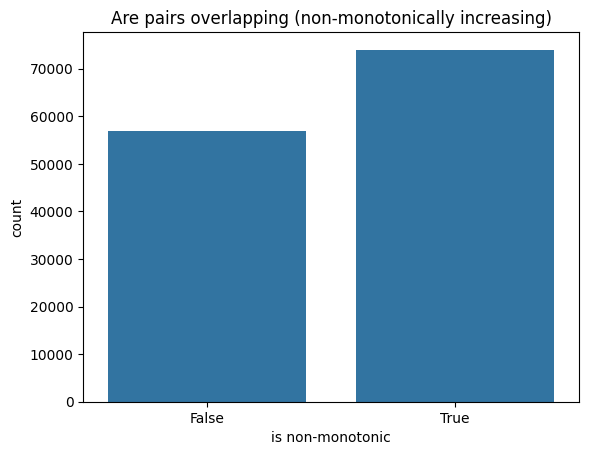

In [ ]:
plt.title("Are pairs overlapping (non-monotonically increasing)")
sns.barplot((~times_df["monotonic"]).value_counts())
plt.xlabel("is non-monotonic")

In [ ]:
times_df[~times_df["monotonic"]]

,admission_time,orin_time,anstart_time,opstart_time,cpbon_time,cpboff_time,opend_time,orout_time,anend_time,inhosp_death_time,discharge_time,allcause_death_time,monotonic
0,0,1110,1120.0,1140.0,NaN,NaN,1230.0,1245,1235.0,NaN,7195,NaN,False
1,0,1340,1345.0,1370.0,NaN,NaN,1540.0,1550,1540.0,69860.0,70555,106560.0,False
2,0,62165,62170.0,62200.0,NaN,NaN,62380.0,62395,62370.0,NaN,178555,718560.0,False
4,0,17945,17950.0,17970.0,NaN,NaN,18070.0,18080,18070.0,NaN,25915,NaN,False
5,0,1980,1990.0,2020.0,NaN,NaN,2070.0,2075,2070.0,NaN,5755,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
130928,0,2325,2330.0,2355.0,NaN,NaN,2460.0,2470,2465.0,NaN,7195,NaN,False
130937,0,1345,1345.0,1350.0,NaN,NaN,1390.0,1405,1400.0,NaN,89275,NaN,False
130944,0,2245,2250.0,2285.0,NaN,NaN,2360.0,2370,2365.0,NaN,8635,NaN,False
130945,0,2520,2525.0,2560.0,NaN,NaN,2630.0,2635,2630.0,NaN,8635,NaN,False


28917.28253760628 16135.0


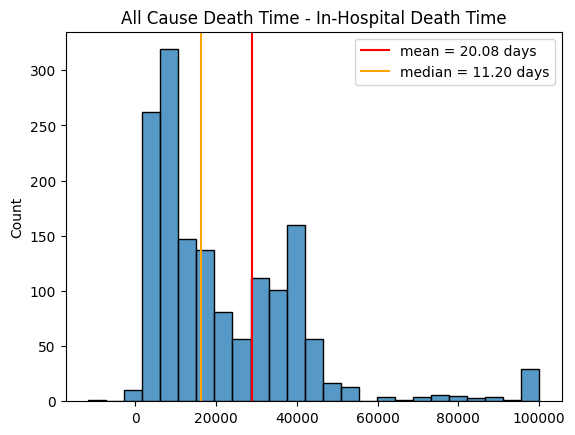

In [ ]:
# death_time_within = lambda t: (times_df["inhosp_death_time"] - times_df["allcause_death_time"]).abs() <= t
death_time_within = lambda t: (times_df["allcause_death_time"] - times_df["inhosp_death_time"]) <= t


abs_diff = (times_df["allcause_death_time"] - times_df["inhosp_death_time"])
# abs_diff = (times_df["inhosp_death_time"] - times_df["allcause_death_time"]).abs()
plt.title("All Cause Death Time - In-Hospital Death Time")
# plt.title("Abs(In-Hospital Death Time - All Cause Death Time)")
ax = sns.histplot(abs_diff.clip(upper=1e5))
ax.axvline(abs_diff.mean(), color="red", label=f"mean = {(abs_diff.mean() / (60 * 24)):.2f} days")
ax.axvline(abs_diff.median(), color="orange", label=f"median = {(abs_diff.median() / (60 * 24)):.2f} days")
ax.legend()
print(abs_diff.mean(), abs_diff.median())
plt.show()

<Axes: ylabel='count'>

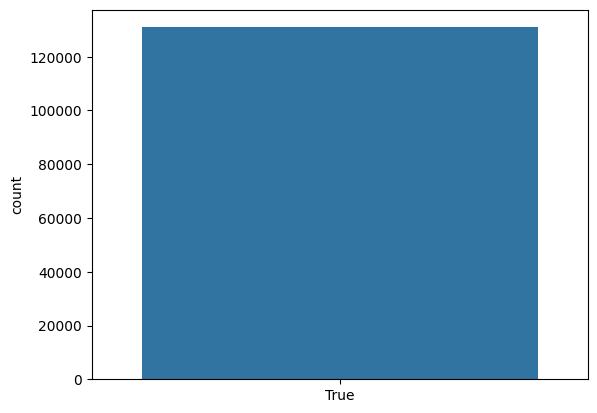

In [ ]:
sns.barplot((operations["orin_time"] < operations["orout_time"]).value_counts())

<Axes: ylabel='count'>

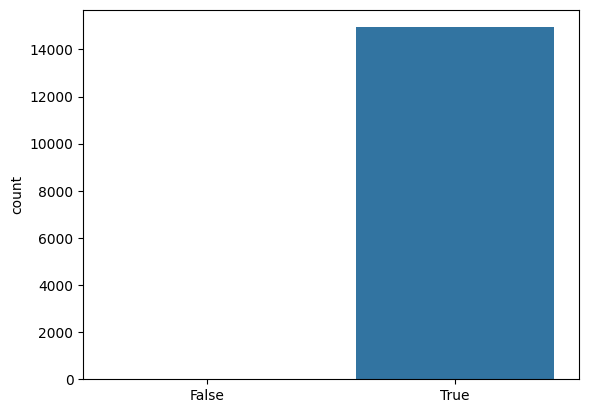

In [ ]:
icu_df = operations[["icuin_time", "icuout_time"]].dropna()
sns.barplot((icu_df["icuin_time"] < icu_df["icuout_time"]).value_counts())

<Axes: ylabel='count'>

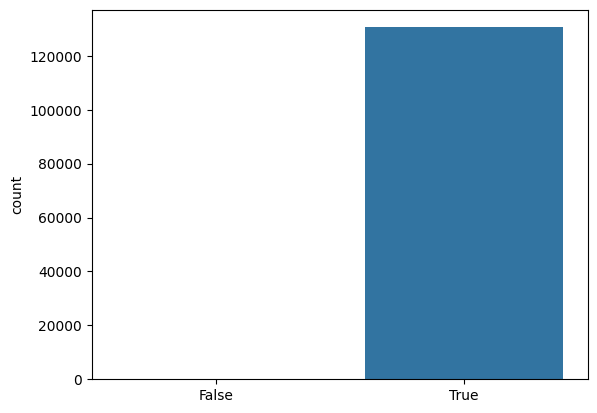

In [ ]:
an_time = operations[["anstart_time", "anend_time"]].dropna()
sns.barplot((an_time["anstart_time"] < an_time["anend_time"]).value_counts())

<Axes: ylabel='count'>

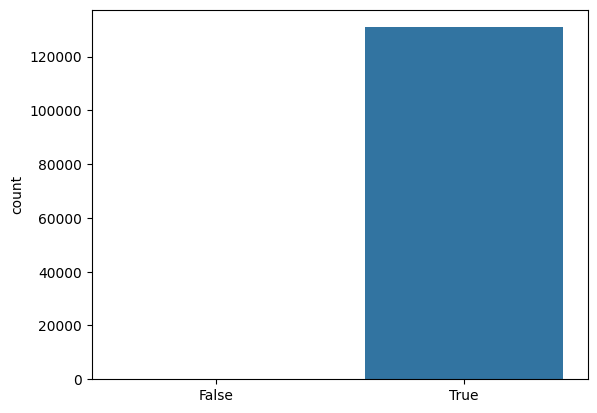

In [ ]:
op_time = operations[["opstart_time", "opend_time"]].dropna()
sns.barplot((op_time["opstart_time"] < op_time["opend_time"]).value_counts())

<Axes: ylabel='count'>

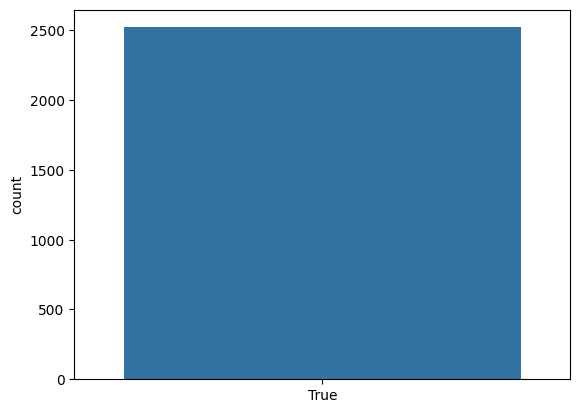

In [ ]:
cpb_time = operations[["cpbon_time", "cpboff_time"]].dropna()
sns.barplot((cpb_time["cpbon_time"] < cpb_time["cpboff_time"]).value_counts())

<Axes: ylabel='count'>

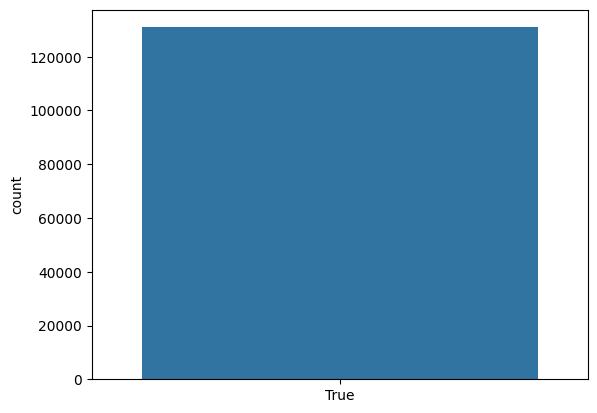

In [ ]:
sns.barplot((operations["admission_time"] < operations["discharge_time"]).value_counts())

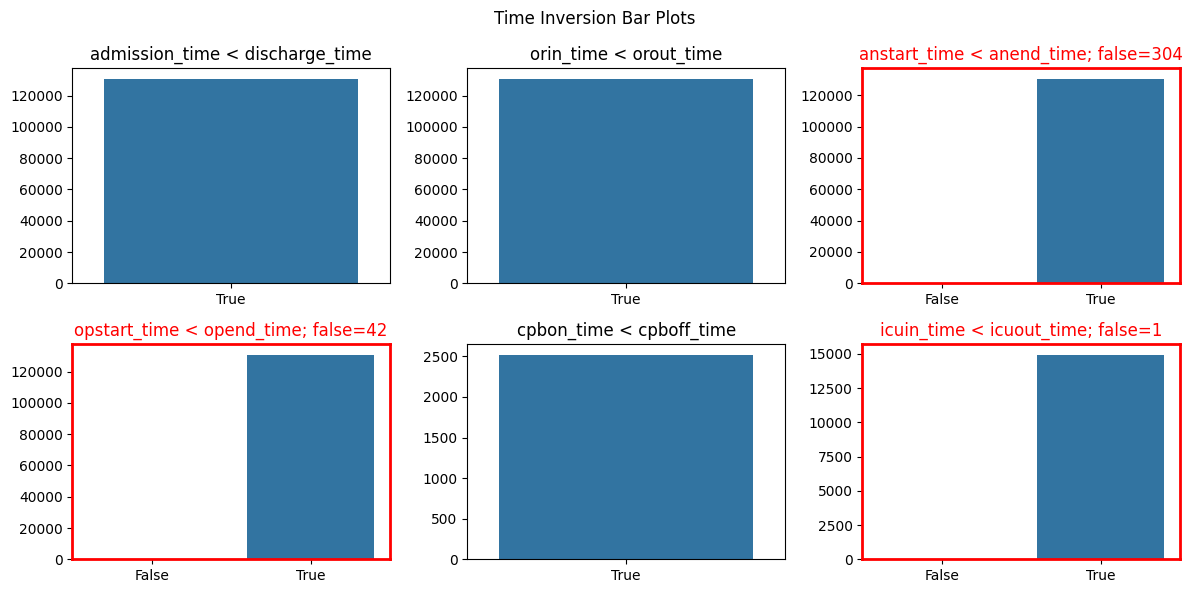

In [ ]:
time_pairs = [
    ("admission_time", "discharge_time"),
    ("orin_time", "orout_time"),
    ("anstart_time", "anend_time"),
    ("opstart_time", "opend_time"),
    ("cpbon_time", "cpboff_time"),
    ("icuin_time", "icuout_time"),
]

n = len(time_pairs)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3))

axes = axes.flatten()

for i, (start, end) in enumerate(time_pairs):
    ax = axes[i]
    operations_clean = operations[[start, end]].dropna(how="all")
    operations_clean = operations_clean.fillna(False)
    counts = (operations_clean[start] < operations_clean[end]).value_counts()

    sns.barplot(counts, ax=ax)

    ax.set_title(f"{start} < {end}")
    ax.set_xlabel("")
    ax.set_ylabel("")

    if False in counts.index and counts.loc[False] > 0:
        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(2)
        ax.set_title(f"{start} < {end}; false={counts.loc[False]}", color="red")

for j in range(i+1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Time Inversion Bar Plots")
plt.tight_layout()
plt.show()

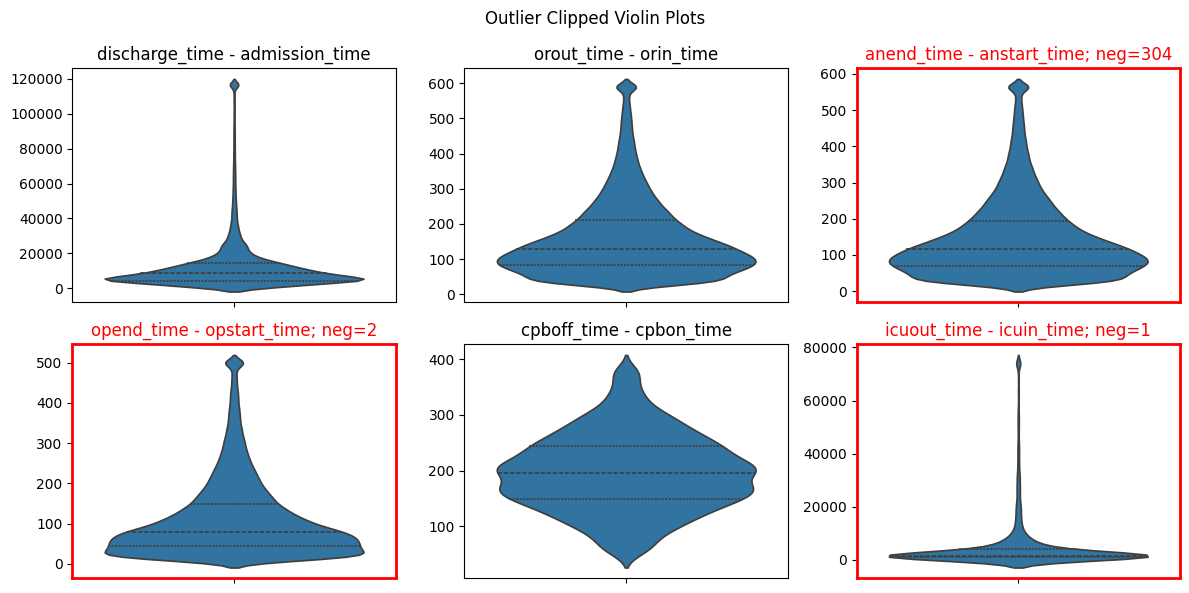

In [ ]:
time_pairs = [
    ("admission_time", "discharge_time"),
    ("orin_time", "orout_time"),
    ("anstart_time", "anend_time"),
    ("opstart_time", "opend_time"),
    ("cpbon_time", "cpboff_time"),
    ("icuin_time", "icuout_time"),
]

n = len(time_pairs)
cols = 3
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3))

axes = axes.flatten()

for i, (start, end) in enumerate(time_pairs):
    ax = axes[i]
    operations_clean = operations[[start, end]].dropna(how="all")
    operations_clean = operations_clean.fillna(False)
    differences = (operations_clean[end] - operations_clean[start])
    lb = differences.quantile(0.01)
    ub = differences.quantile(0.99)
    sns.violinplot(differences.clip(lower=lb, upper=ub), ax=ax, inner="quartile")

    ax.set_title(f"{end} - {start}")
    ax.set_xlabel("")
    ax.set_ylabel("")

    if differences.min() < 0:
        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(2)
        ax.set_title(f"{end} - {start}; neg={(differences < 0).sum()}", color="red")

for j in range(i+1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Outlier Clipped Violin Plots")
plt.tight_layout()
plt.show()

## Labs
### Checking that values are in plausible range

In [ ]:
labs

,subject_id,chart_time,item_name,value
0,133338290,86155,total_protein,6.9
1,133338290,86155,sodium,140.0
2,133338290,86155,potassium,4.4
3,133338290,86155,platelet,152.0
4,133338290,93150,glucose,120.0
...,...,...,...,...
19503330,155658270,35270,hb,15.0
19503331,155658270,35270,hct,44.1
19503332,155658270,35270,platelet,245.0
19503333,155658270,35270,seg,79.9


In [ ]:
labs["item_name"].unique()

array(['total_protein', 'sodium', 'potassium', 'platelet', 'glucose',
       'wbc', 'alt', 'chloride', 'lymphocyte', 'phosphorus', 'albumin',
       'fibrinogen', 'creatinine', 'ptinr', 'total_bilirubin', 'alp',
       'aptt', 'calcium', 'bun', 'ast', 'crp', 'hb', 'hct', 'seg', 'ica',
       'ph', 'paco2', 'pao2', 'hco3', 'sao2', 'lacate', 'ckmb',
       'troponin_i', 'ck', 'hba1c', 'be', 'troponin_t', 'd_dimer'],
      dtype=object)

In [ ]:
labs_agg = labs.groupby("item_name")["value"].agg(
    min="min",
    q25=lambda x: x.quantile(0.25),
    median="median",
    q75=lambda x: x.quantile(0.75),
    max="max",
    mean="mean",
    std="std",
    count="count",
    na=lambda x: x.isna().sum(),
)

In [ ]:
factors = labs["item_name"].unique()
factors

array(['total_protein', 'sodium', 'potassium', 'platelet', 'glucose',
       'wbc', 'alt', 'chloride', 'lymphocyte', 'phosphorus', 'albumin',
       'fibrinogen', 'creatinine', 'ptinr', 'total_bilirubin', 'alp',
       'aptt', 'calcium', 'bun', 'ast', 'crp', 'hb', 'hct', 'seg', 'ica',
       'ph', 'paco2', 'pao2', 'hco3', 'sao2', 'lacate', 'ckmb',
       'troponin_i', 'ck', 'hba1c', 'be', 'troponin_t', 'd_dimer'],
      dtype=object)

In [ ]:
labs_agg

,min,q25,median,q75,max,mean,std,count,na
item_name,,,,,,,,,
albumin,2.300,3.000,3.600,4.100,4.70000,3.542797,0.629010,647361,0
alp,33.000,52.000,68.000,93.000,296.00000,82.753843,51.723786,606324,0
alt,6.000,13.000,20.000,35.000,209.00000,33.229501,39.122312,619327,0
aptt,24.000,28.500,31.200,34.700,70.60000,33.557161,9.157849,317403,0
ast,11.000,18.000,23.000,35.000,180.00000,33.673414,31.770388,619231,0
be,-9.600,-2.000,0.400,2.900,10.70000,0.451117,4.292634,238140,0
bun,6.000,10.000,15.000,21.000,64.00000,18.235439,12.574422,678674,0
calcium,7.300,8.100,8.600,9.100,10.00000,8.618190,0.672700,674206,0
chloride,92.000,100.000,102.000,106.000,113.00000,102.710173,4.613058,720703,0


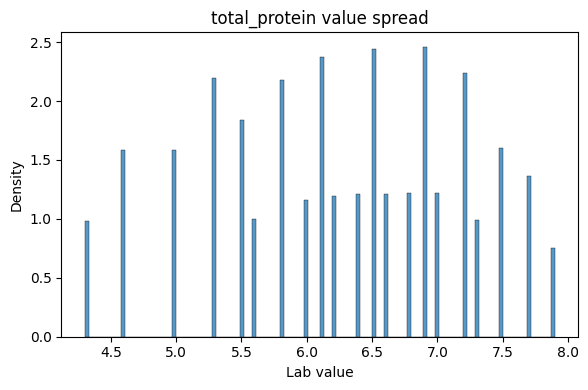

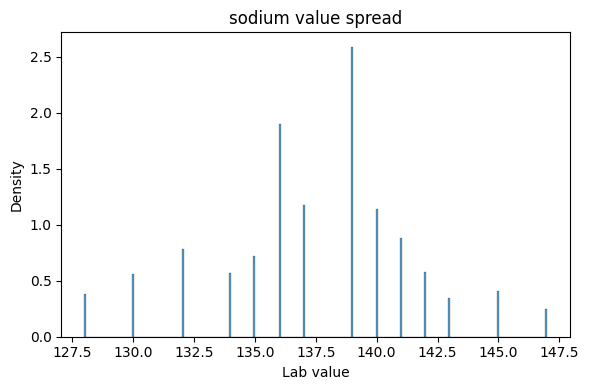

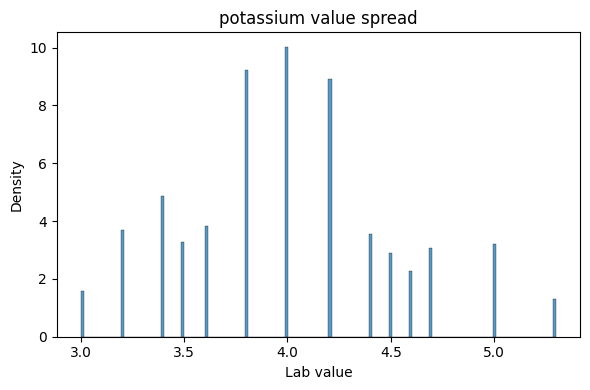

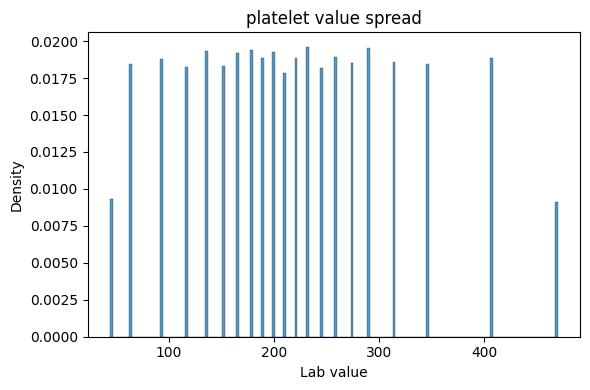

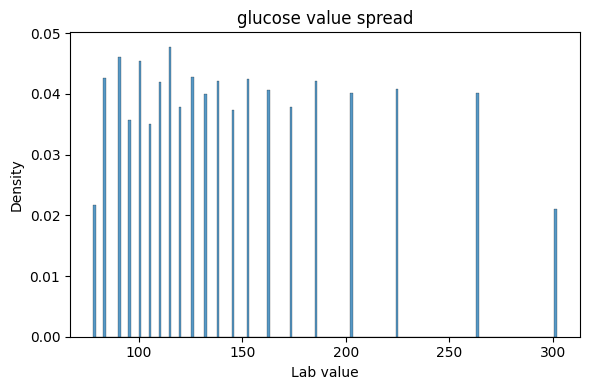

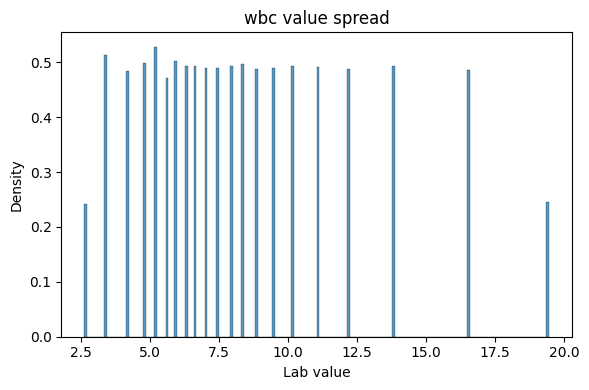

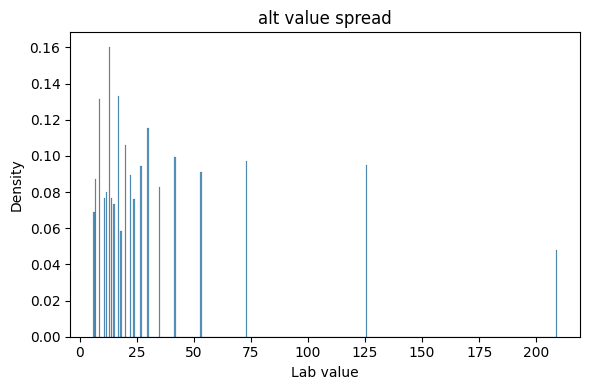

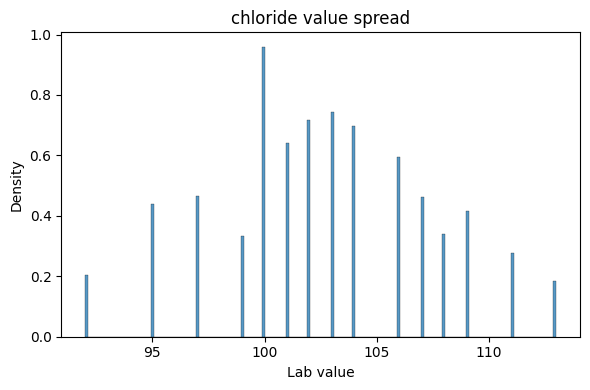

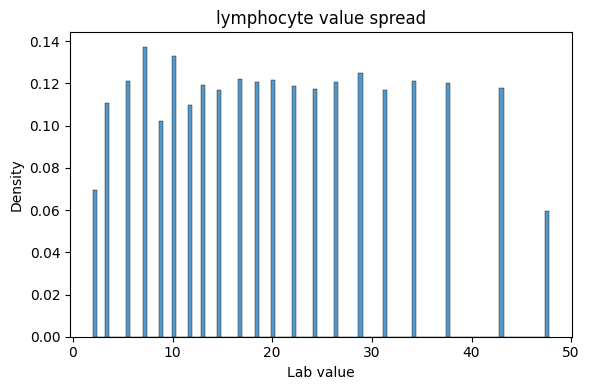

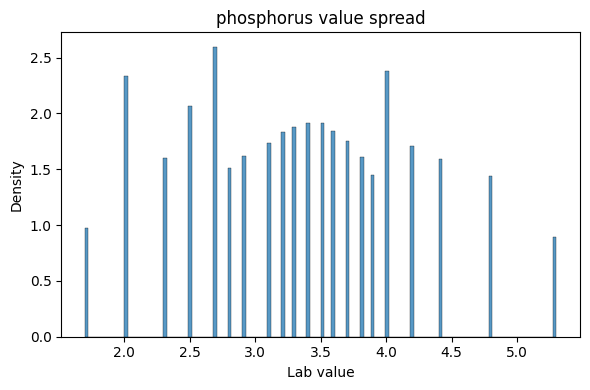

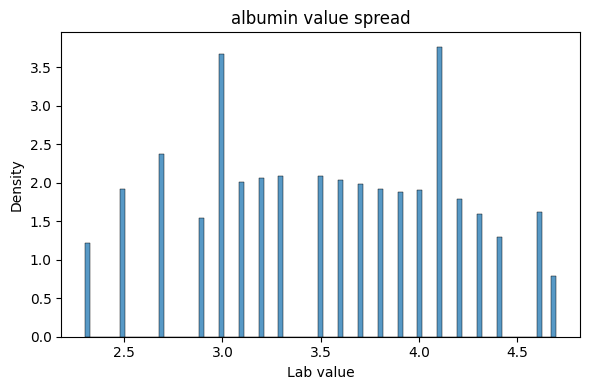

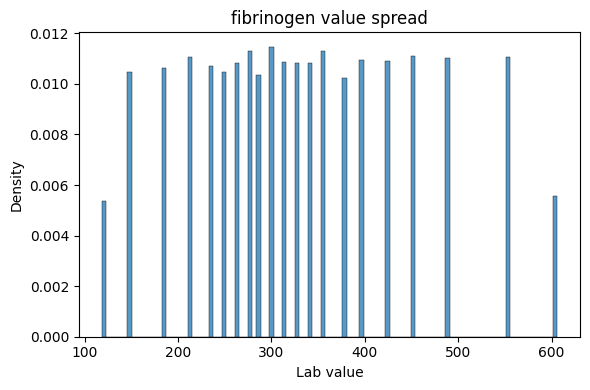

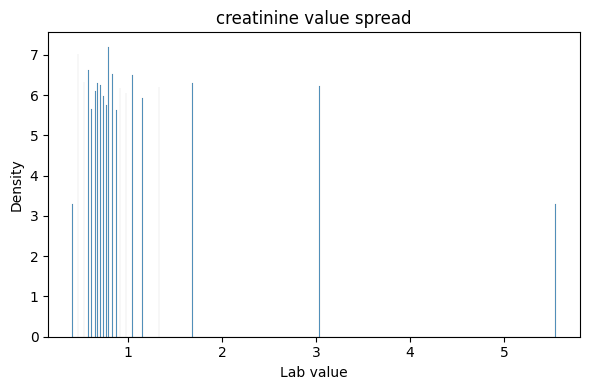

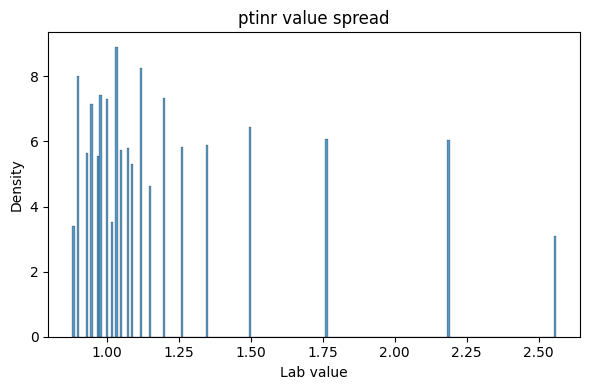

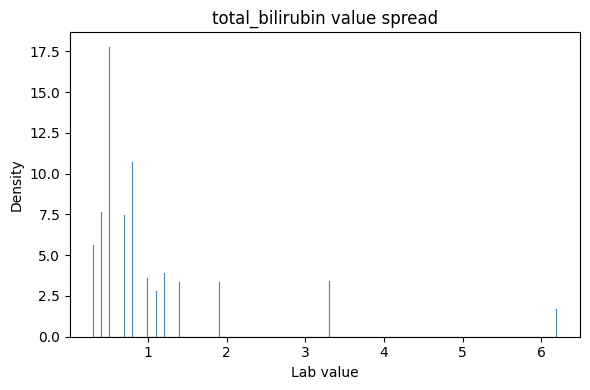

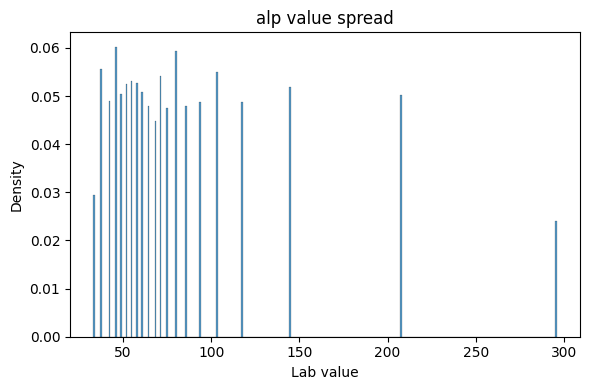

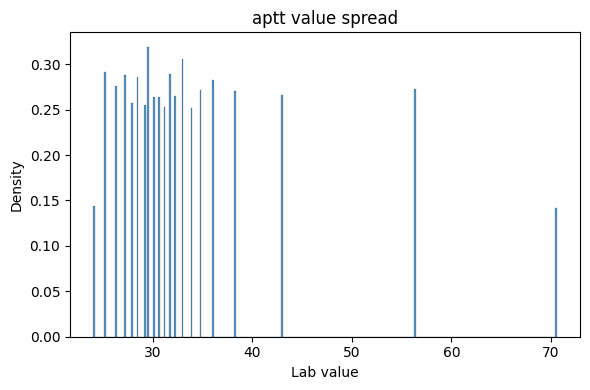

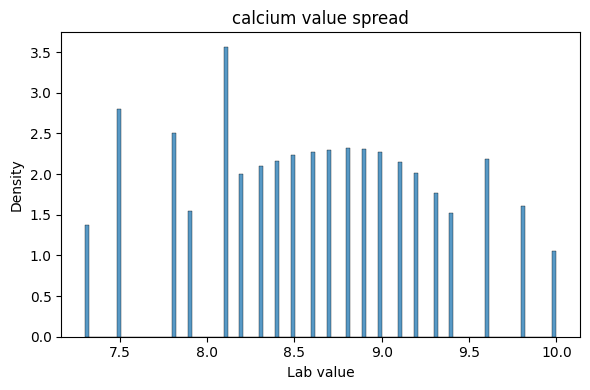

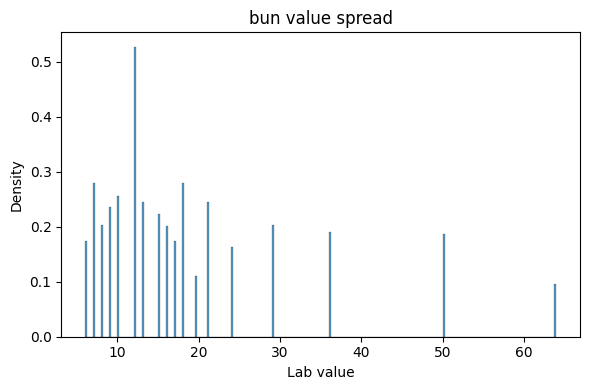

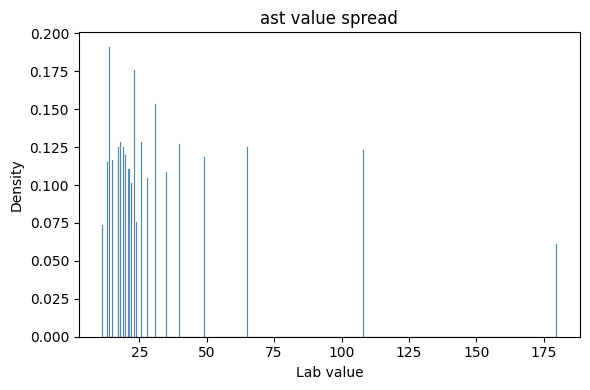

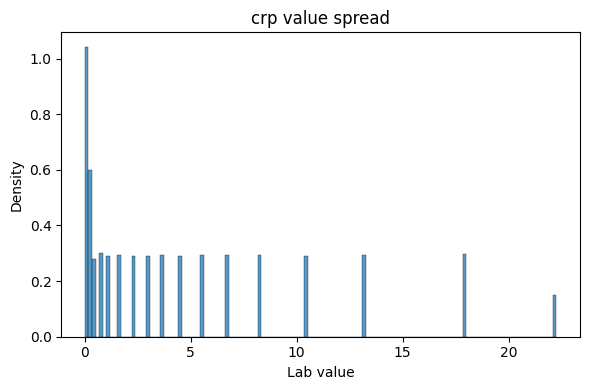

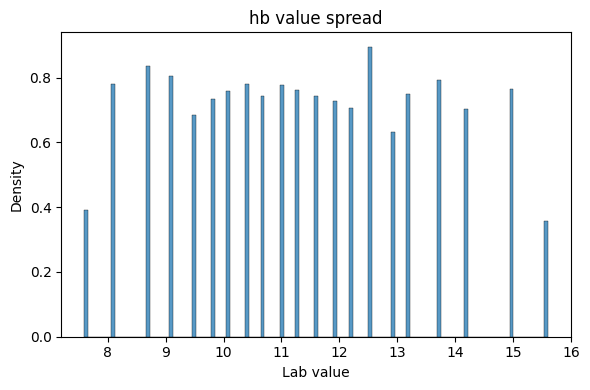

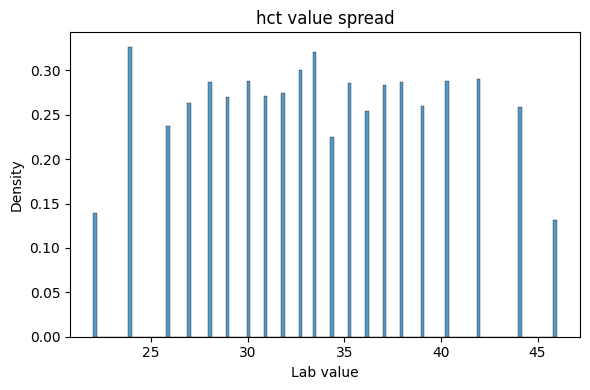

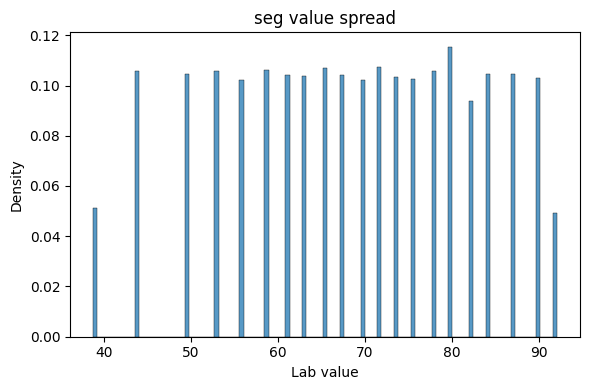

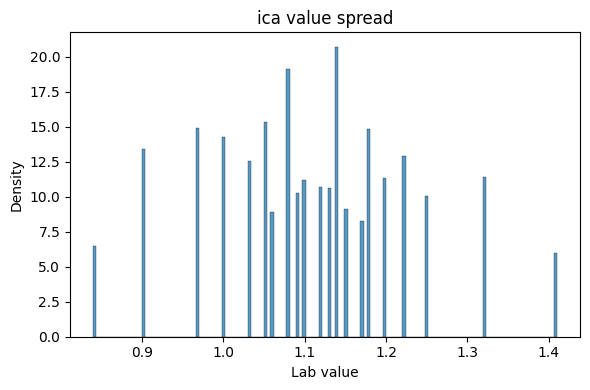

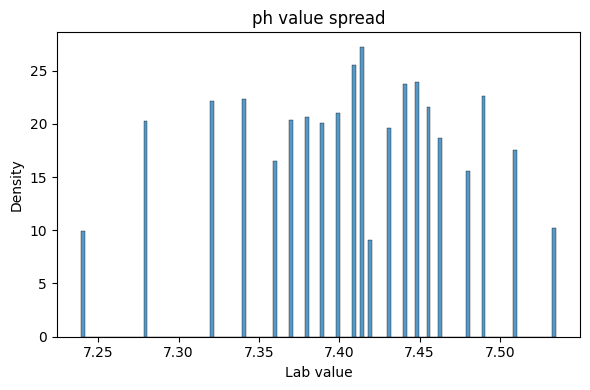

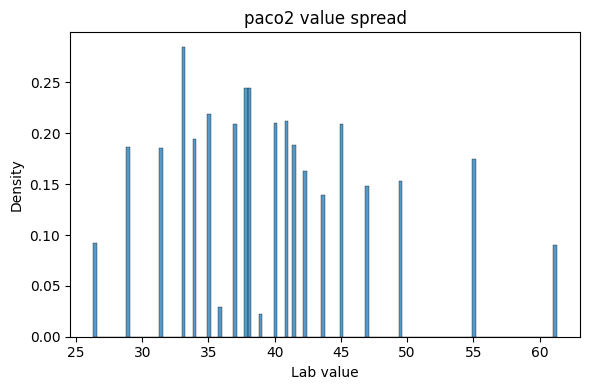

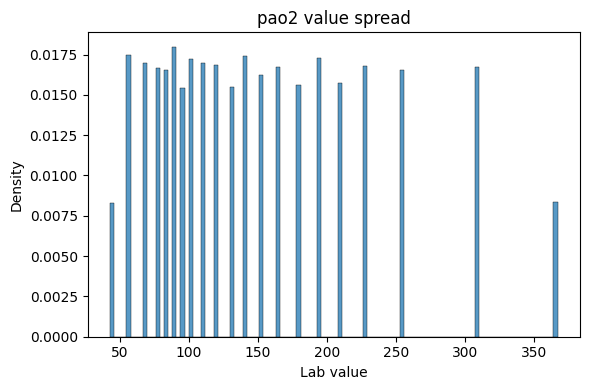

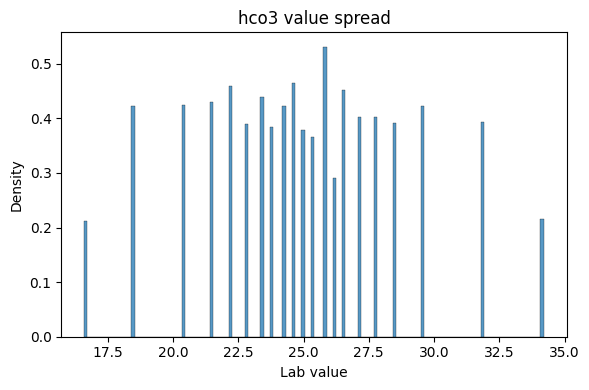

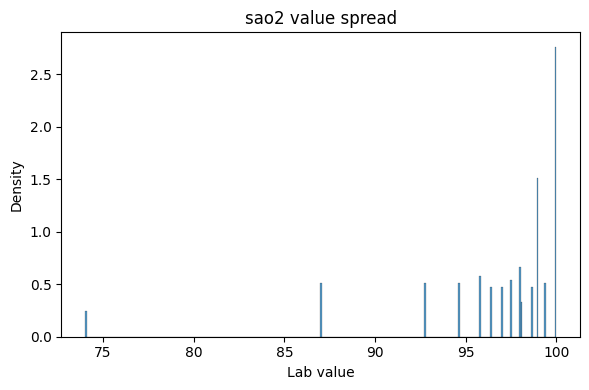

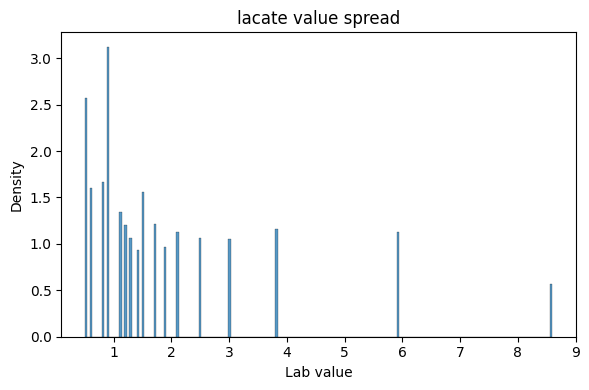

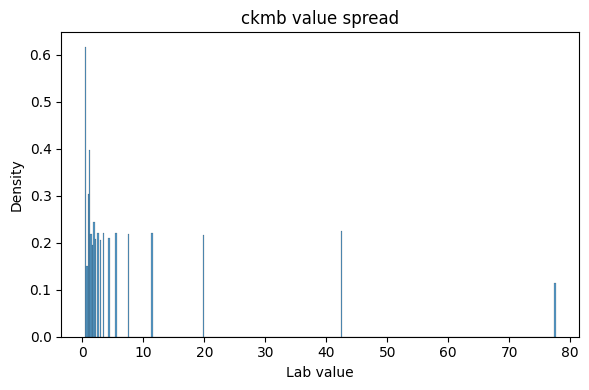

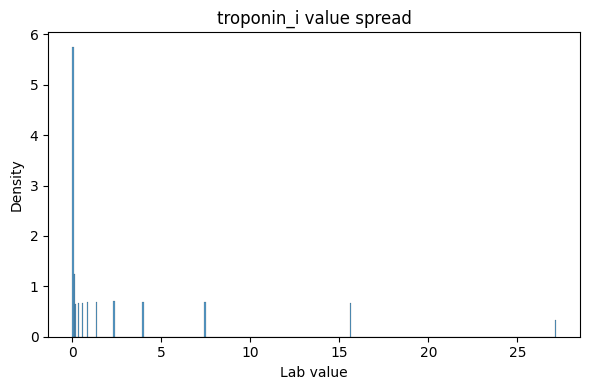

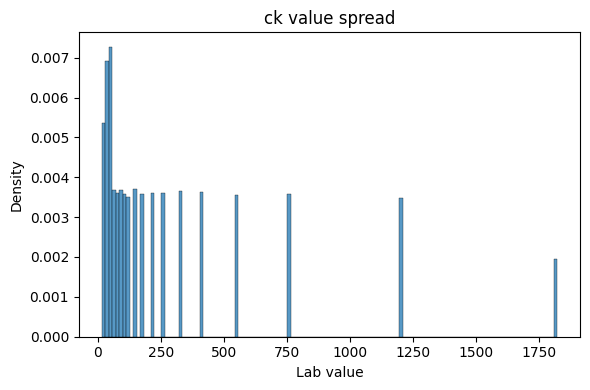

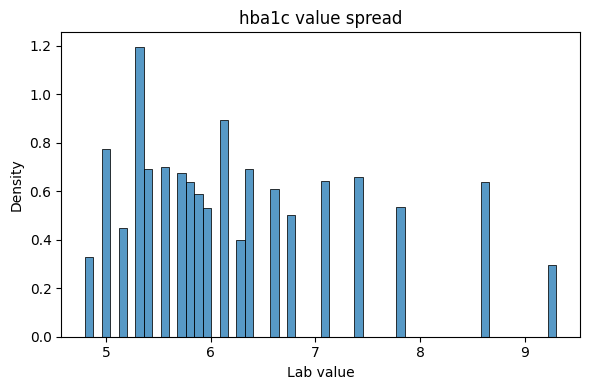

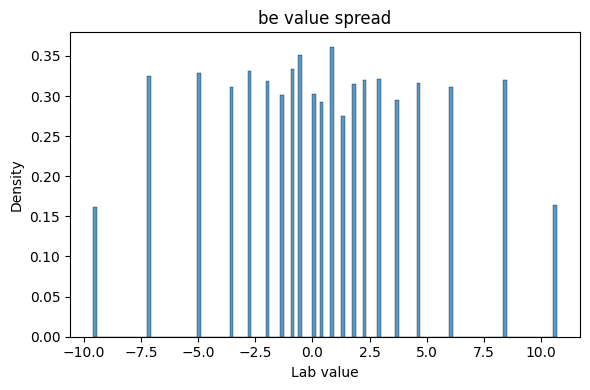

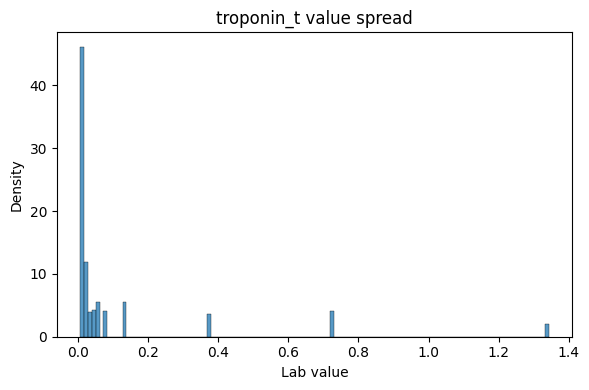

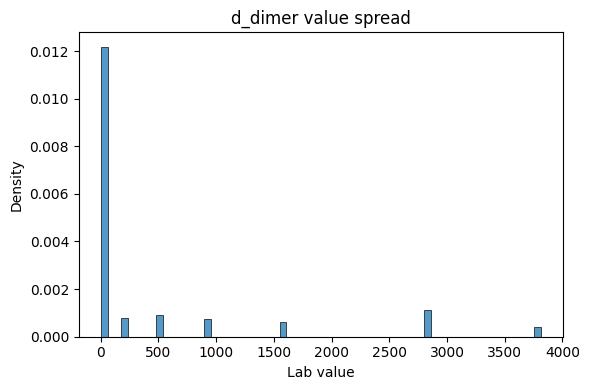

In [ ]:
for factor in factors:
    factor_df = labs[labs["item_name"] == factor]

    plt.figure(figsize=(6,4))
    sns.histplot(factor_df["value"], stat="density")
    plt.title(f"{factor} value spread")
    plt.xlabel("Lab value")
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

In [ ]:
# While the references were based on "normal" ranges, the lower and upper boundaries have been adjusted
# for outlier deteciton in critically ill patients or patients with rare conditions

# Credits to ChatGPT for helping us find the following sources:

# Citations:
# NBME Laboratory Reference Values — general adult serum chemistry & metabolic panel reference.(https://www.nbme.org/sites/default/files/2025-03/NBME_Laboratory_Reference_Values.pdf)
# Medscape Lab Values Guide — normal adult lab values across multiple analytes (https://emedicine.medscape.com/article/2172316-overview)
# NCBI Bookshelf Normal Reference Ranges — Complete Blood Count and Differential values. (https://www.ncbi.nlm.nih.gov/books/NBK615342/)
# Interpretation of Blood Clotting Studies — PT, INR, PTT normal interpretation context. (https://www.ncbi.nlm.nih.gov/books/NBK604215/)
# MedlinePlus Medical Encyclopedia — PT/INR reference information from a U.S. clinical resource.(https://medlineplus.gov/ency/article/003652.htm)

lab_weird = {
    "sodium": (120, 160),
    "potassium": (2, 7),
    "chloride": (80, 120),
    "calcium": (6, 12),
    "phosphorus": (0.5, 10),
    "glucose": (20, 600),
    "bun": (1, 200),
    "creatinine": (0.1, 15),
    "total_protein": (2, 10),
    "albumin": (1, 6),
    "total_bilirubin": (0.1, 40),
    "ast": (0, 5000),
    "alt": (0, 5000),
    "alp": (10, 2000),
    "wbc": (0.1, 200),
    "hb": (3, 25),
    "hct": (5, 75),
    "platelet": (5, 1500),
    "seg": (0, 100),
    "lymphocyte": (0, 100),
    "ptinr": (0.8, 10),
    "aptt": (10, 200),
    "crp": (0, 500),
    "fibrinogen": (50, 1200),
    "d_dimer": (0, 20000),
    "ph": (6.8, 7.8),
    "paco2": (10, 120),
    "pao2": (20, 600),
    "hco3": (5, 50),
    "sao2": (0, 100),
    "ica": (0.5, 2.0),
    "be": (-30, 30),
    "troponin_i": (0, 200),
    "troponin_t": (0, 50),
    "ck": (0, 20000),
    "ckmb": (0, 500),
    "hba1c": (3, 15),
    "lacate": (0, 20),
}

lab_normal = {
    "sodium": (135, 146),
    "potassium": (3.5, 5.0),
    "chloride": (95, 105),
    "calcium": (8.4, 10.2),
    "phosphorus": (2.5, 4.5),
    "glucose": (70, 140),
    "bun": (7, 20),
    "creatinine": (0.6, 1.3),
    "total_protein": (6.0, 8.3),
    "albumin": (3.5, 5.0),
    "total_bilirubin": (0.1, 1.2),
    "ast": (10, 40),
    "alt": (7, 56),
    "alp": (40, 130),
    "wbc": (4.0, 11.0),
    "hb": (12, 18),
    "hct": (36, 54),
    "platelet": (150, 400),
    "seg": (40, 70),
    "lymphocyte": (20, 40),
    "ptinr": (0.8, 1.2),
    "aptt": (24, 33),
    "fibrinogen": (200, 400),
    "d_dimer": (0, 500),
    "ph": (7.35, 7.45),
    "paco2": (35, 45),
    "pao2": (80, 100),
    "hco3": (22, 28),
    "sao2": (95, 100),
    "ica": (1.1, 1.3),
    "be": (-2, 2),
    "troponin_i": (0, 0.04),
    "troponin_t": (0, 0.01),
    "ck": (20, 200),
    "ckmb": (0, 5),
    "hba1c": (4, 5.6),
    "lacate": (0.5, 2.0)
}

In [ ]:
def weird_value(lab, values):
    if lab in lab_weird: # not in wide range
        lower, upper = lab_weird[lab]
        return values.quantile(0.1) < lower or values.quantile(0.9) > upper
    elif values.std() < 1e-2 or values.quantile(0.75) - values.quantile(0.25) < 1e-2: # all entries = very close
        return True
    elif values.mean() > 5 * values.median(): # very skewed
        return True
    return False

def abnormal_value(lab, values):
    if lab in lab_normal: # not in normal range
        lower, upper = lab_normal[lab]
        return values.quantile(0.1) < lower or values.quantile(0.9) > upper
    return False

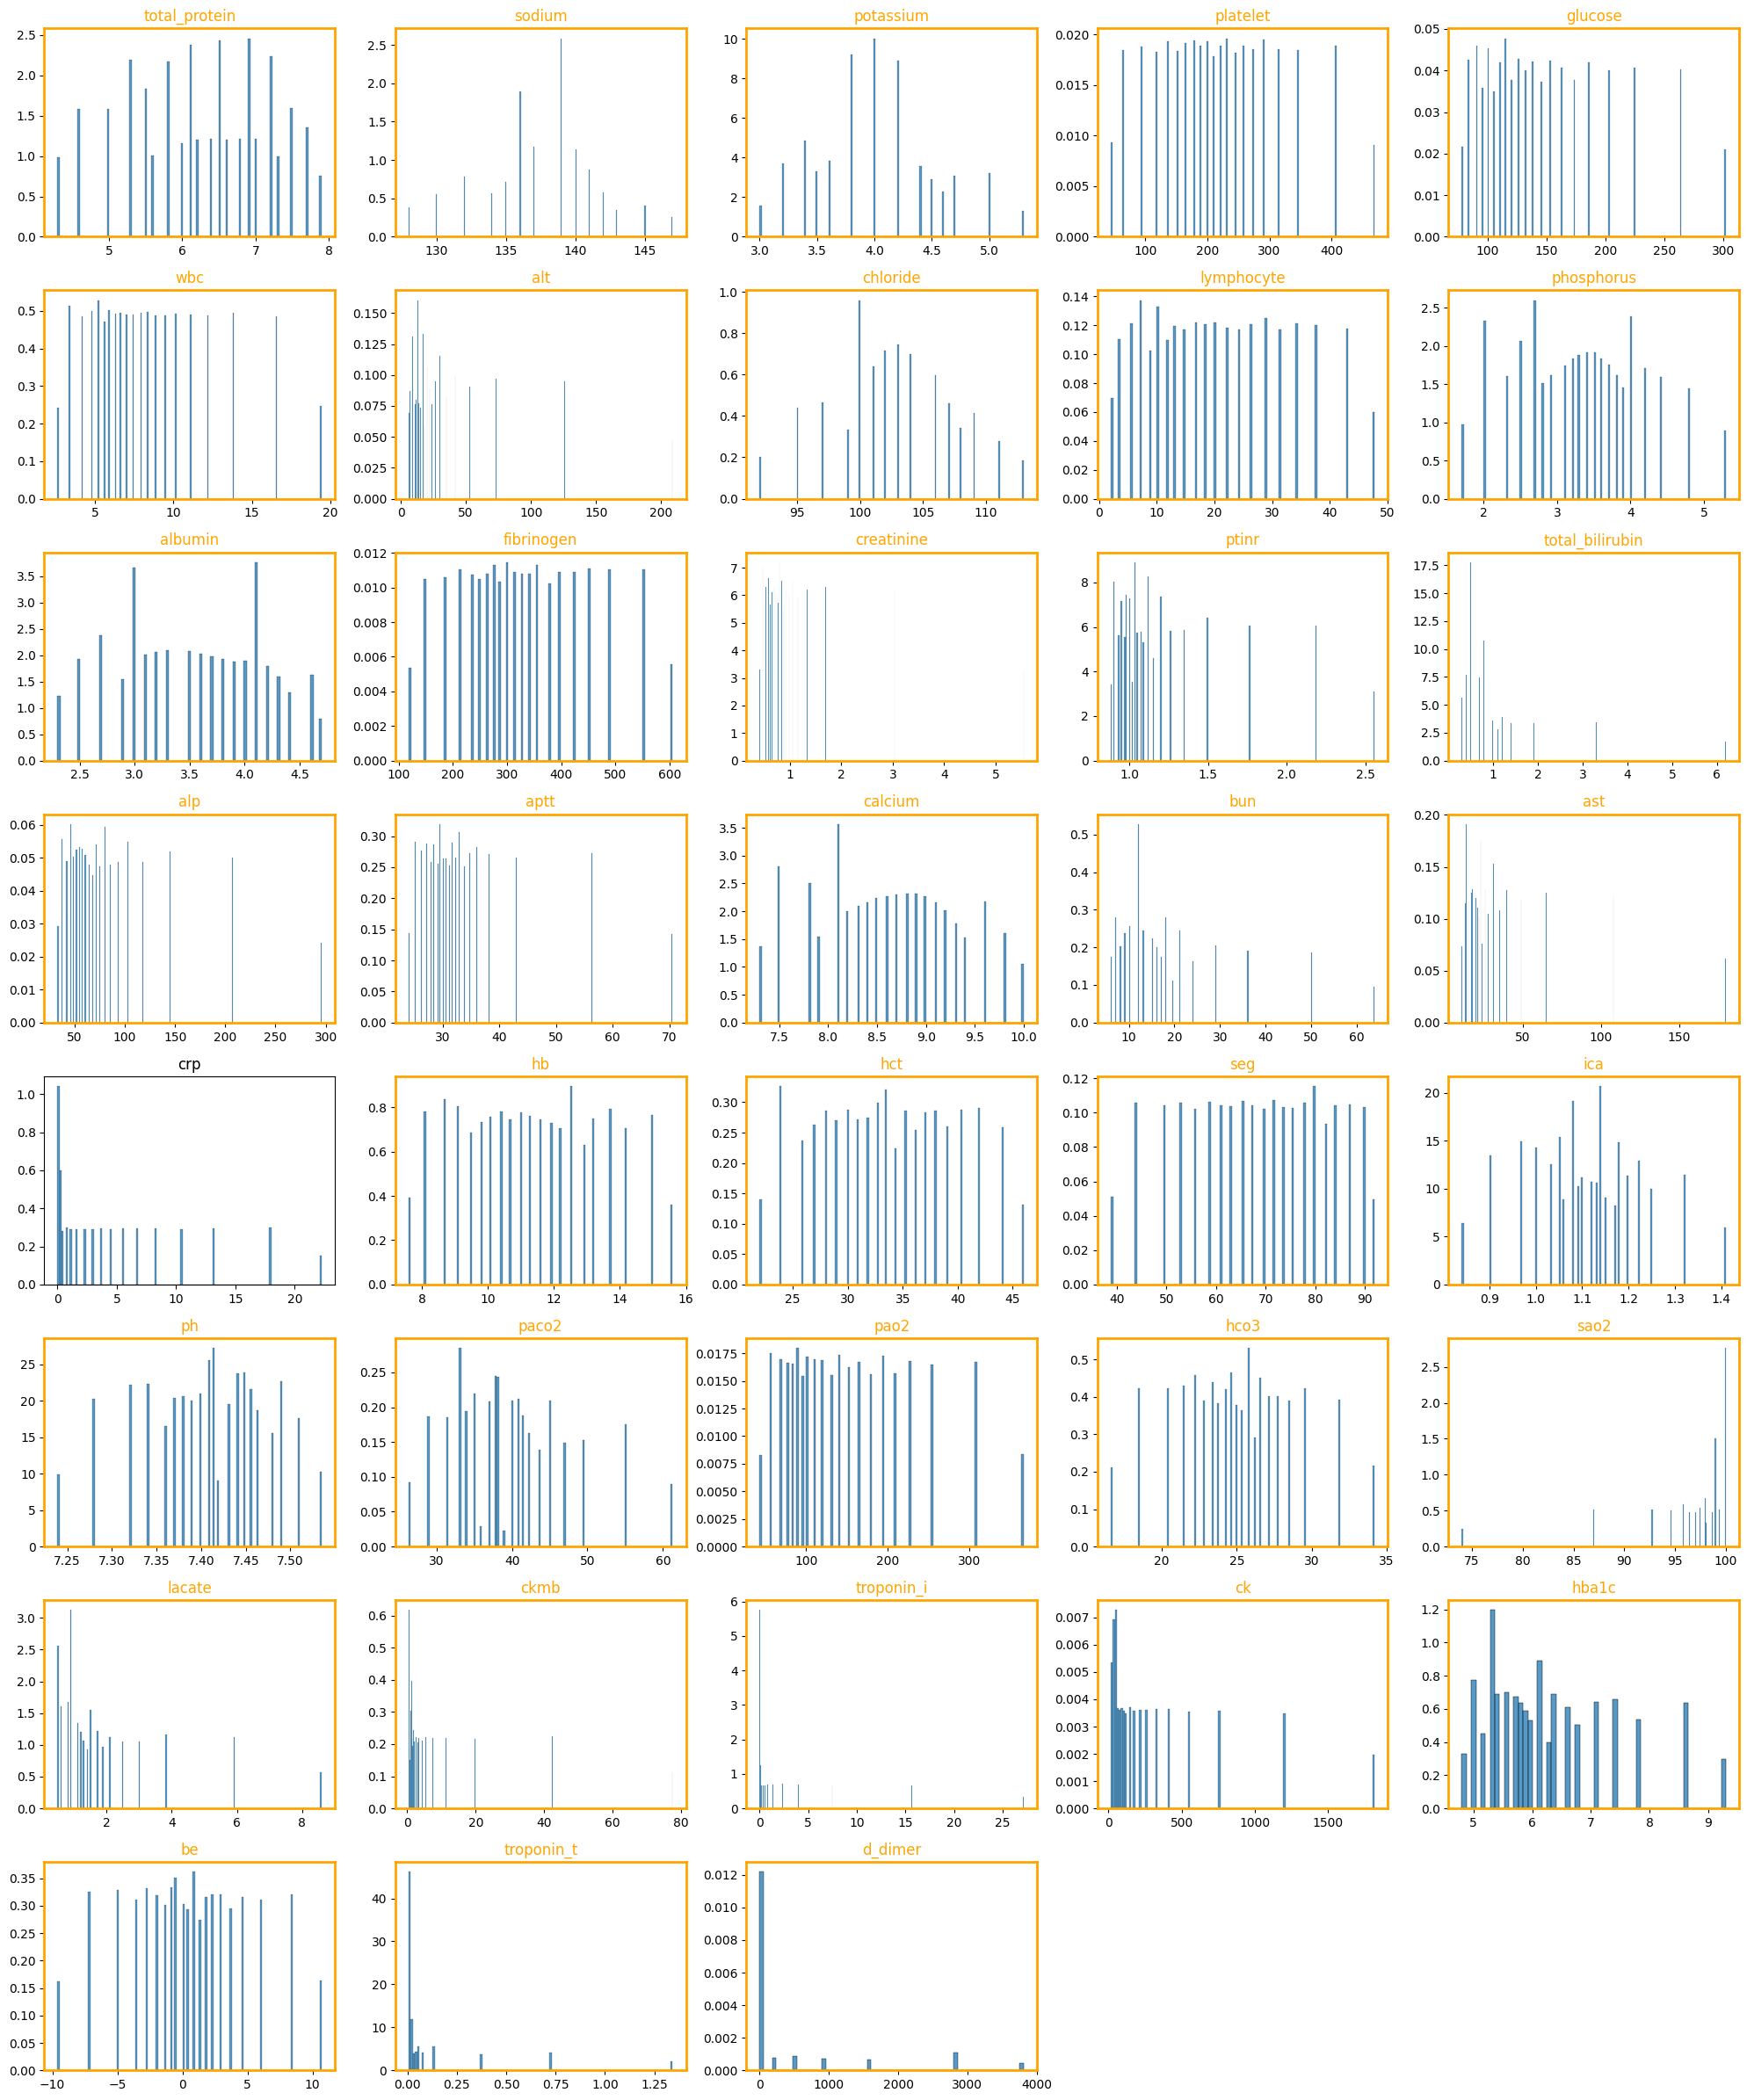

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns

n = len(factors)

cols = 5
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3))

axes = axes.flatten()

for i, factor in enumerate(factors):
    ax = axes[i]
    factor_df = labs[labs["item_name"] == factor]["value"].dropna()

    sns.histplot(factor_df, ax=ax, stat="density")

    ax.set_title(factor)
    ax.set_xlabel("")
    ax.set_ylabel("")

    if weird_value(factor, factor_df):
        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(2)
        ax.set_title(factor, color="red")
    elif abnormal_value(factor, factor_df):
        for spine in ax.spines.values():
            spine.set_edgecolor("orange")
            spine.set_linewidth(2)
        ax.set_title(factor, color="orange")

for j in range(i+1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()